In [1]:
import pandas as pd

alibaba = pd.read_csv("DATASET/alibaba_microservices_large.csv")

print("Total connections:", len(alibaba))
print("Unique source nodes:", alibaba["source_node"].nunique())
print("Unique target nodes:", alibaba["target_node"].nunique())
print("Bottleneck counts:")
print(alibaba["bottleneck_flag"].value_counts())

Total connections: 2955
Unique source nodes: 100
Unique target nodes: 100
Bottleneck counts:
bottleneck_flag
0    2788
1     167
Name: count, dtype: int64


Dataset shape: (2955, 7)

First five rows:


,source_node,target_node,protocol,avg_latency_ms,data_transfer_mb,error_rate_percent,bottleneck_flag
0,service_54,service_15,grpc,44.96,4681.62,0.37,0
1,service_48,service_31,tcp,16.18,1595.86,0.42,0
2,service_33,service_49,tcp,29.42,2838.19,0.30,0
3,service_56,service_6,http,26.81,3596.74,1.50,0
4,service_32,service_41,udp,14.15,2437.72,0.15,0



Column information:
<class 'pandas.DataFrame'>
RangeIndex: 2955 entries, 0 to 2954
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   source_node         2955 non-null   str    
 1   target_node         2955 non-null   str    
 2   protocol            2955 non-null   str    
 3   avg_latency_ms      2955 non-null   float64
 4   data_transfer_mb    2955 non-null   float64
 5   error_rate_percent  2955 non-null   float64
 6   bottleneck_flag     2955 non-null   int64  
dtypes: float64(3), int64(1), str(3)
memory usage: 161.7 KB

Missing values per column:
source_node           0
target_node           0
protocol              0
avg_latency_ms        0
data_transfer_mb      0
error_rate_percent    0
bottleneck_flag       0
dtype: int64

Shape after removing duplicates: (2955, 7)

Missing values after preprocessing:
source_node           0
target_node           0
protocol              0
avg_latency_ms       

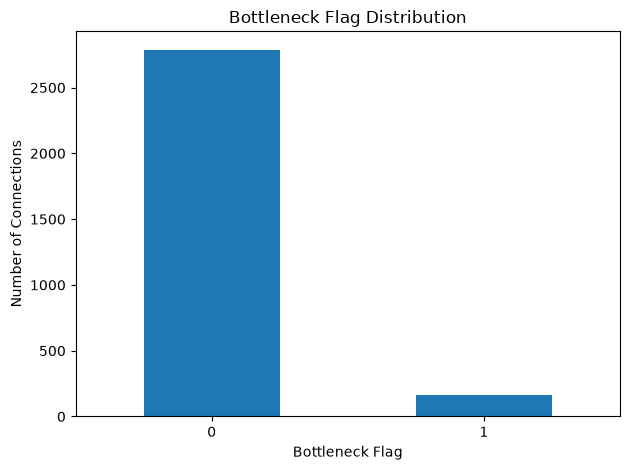

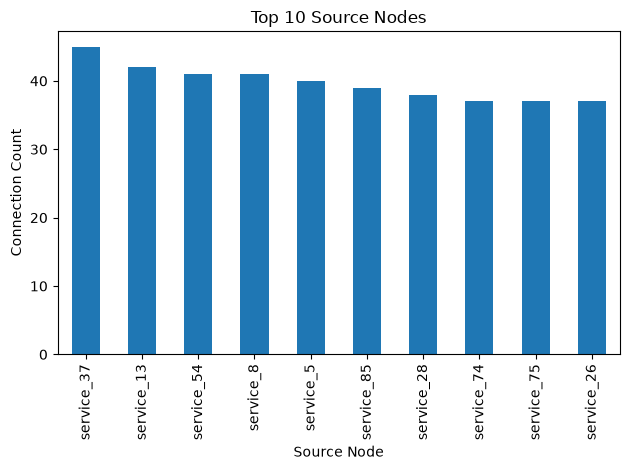

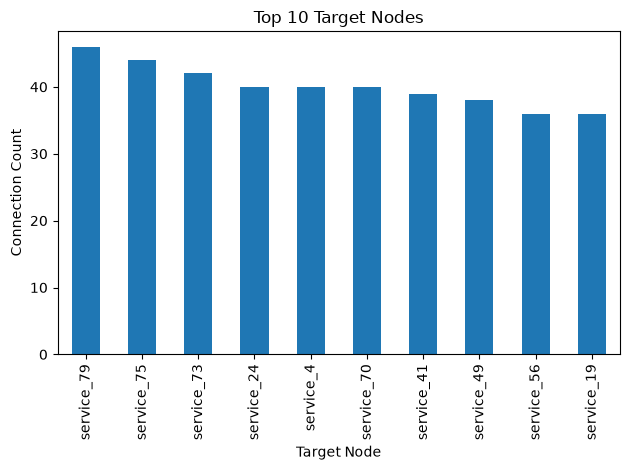

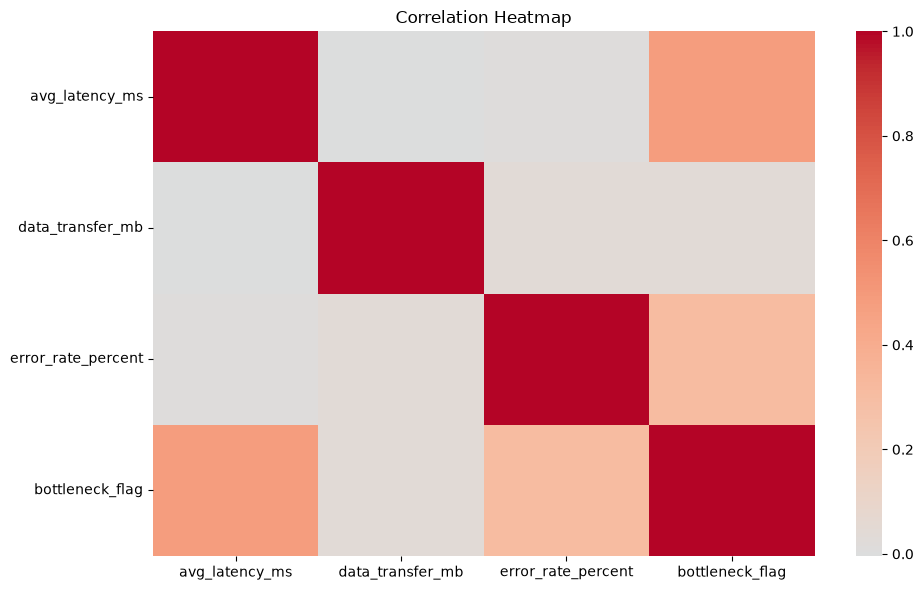


Preprocessing and EDA completed.


In [2]:
# PREPROCESSING AND EXPLORATORY DATA ANALYSIS

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("DATASET/alibaba_microservices_large.csv")

# 1. Dataset overview
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nColumn information:")
df.info()

print("\nMissing values per column:")
print(df.isnull().sum())

# 2. Data preprocessing
df = df.drop_duplicates()

print("\nShape after removing duplicates:", df.shape)

# Fill missing values only for columns where applicable
for col in df.columns:
    if df[col].isnull().any():
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(df[col].median())
        else:
            mode_values = df[col].mode()
            if not mode_values.empty:
                df[col] = df[col].fillna(mode_values.iloc[0])

print("\nMissing values after preprocessing:")
print(df.isnull().sum())

# 3. Bottleneck distribution
if "bottleneck_flag" in df.columns:
    print("\nBottleneck distribution:")
    print(df["bottleneck_flag"].value_counts())

    df["bottleneck_flag"].value_counts().sort_index().plot(
        kind="bar", rot=0
    )
    plt.title("Bottleneck Flag Distribution")
    plt.xlabel("Bottleneck Flag")
    plt.ylabel("Number of Connections")
    plt.tight_layout()
    plt.show()

# 4. Most frequent source nodes
if "source_node" in df.columns:
    df["source_node"].value_counts().head(10).plot(
        kind="bar"
    )
    plt.title("Top 10 Source Nodes")
    plt.xlabel("Source Node")
    plt.ylabel("Connection Count")
    plt.tight_layout()
    plt.show()

# 5. Most frequent target nodes
if "target_node" in df.columns:
    df["target_node"].value_counts().head(10).plot(
        kind="bar"
    )
    plt.title("Top 10 Target Nodes")
    plt.xlabel("Target Node")
    plt.ylabel("Connection Count")
    plt.tight_layout()
    plt.show()

# 6. Correlation heatmap for numeric columns
numeric_df = df.select_dtypes(include="number")

if numeric_df.shape[1] >= 2:
    plt.figure(figsize=(10, 6))
    sns.heatmap(
        numeric_df.corr(),
        cmap="coolwarm",
        center=0
    )
    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()

print("\nPreprocessing and EDA completed.")